<a href="https://colab.research.google.com/github/Mithhuu/Retail-pulse/blob/main/RetailPulse_Day8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/RetailPulse_Cleaned.csv')

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Calculate total sales by region

In [2]:
region_sales = df.groupby('Region')['Sales'].sum()

print("Sales by Region:")
print(region_sales)

Sales by Region:
Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64


Find the highest and lowest sales regions:

In [3]:
highest_sales_region = region_sales.idxmax()
lowest_sales_region = region_sales.idxmin()

print("Highest Sales Region:", highest_sales_region)
print("Lowest Sales Region:", lowest_sales_region)

Highest Sales Region: West
Lowest Sales Region: South


Calculate total profit by region

In [4]:
region_profit = df.groupby('Region')['Profit'].sum()

print("Profit by Region:")
print(region_profit)

Profit by Region:
Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


Find the most profitable region:

In [5]:
best_profit_region = region_profit.idxmax()

print("Most Profitable Region:", best_profit_region)

Most Profitable Region: West


Analyse sales by region and category

In [6]:
regional_category_sales = df.groupby(
    ['Region', 'Category']
)['Sales'].sum()

print(regional_category_sales)

Region   Category       
Central  Furniture          163797.1638
         Office Supplies    167026.4150
         Technology         170416.3120
East     Furniture          208291.2040
         Office Supplies    205516.0550
         Technology         264973.9810
South    Furniture          117298.6840
         Office Supplies    125651.3130
         Technology         148771.9080
West     Furniture          252612.7435
         Office Supplies    220853.2490
         Technology         251991.8320
Name: Sales, dtype: float64


In [7]:
regional_category_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Category',
    aggfunc='sum'
)

print(regional_category_table)

Category    Furniture  Office Supplies  Technology
Region                                            
Central   163797.1638       167026.415  170416.312
East      208291.2040       205516.055  264973.981
South     117298.6840       125651.313  148771.908
West      252612.7435       220853.249  251991.832


Calculate profit margin by region

In [8]:
regional_performance = df.groupby('Region').agg({
    'Sales': 'sum',
    'Profit': 'sum'
})

regional_performance['Profit Margin'] = (
    regional_performance['Profit'] /
    regional_performance['Sales']
) * 100

print(regional_performance.round(2))

             Sales     Profit  Profit Margin
Region                                      
Central  501239.89   39706.36           7.92
East     678781.24   91522.78          13.48
South    391721.90   46749.43          11.93
West     725457.82  108418.45          14.94


Create a regional sales chart

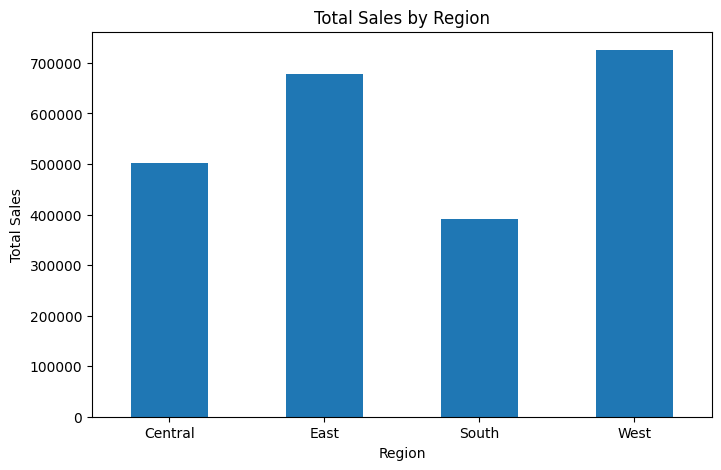

In [9]:
region_sales.plot(kind='bar', figsize=(8,5))

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

Create a regional profit chart

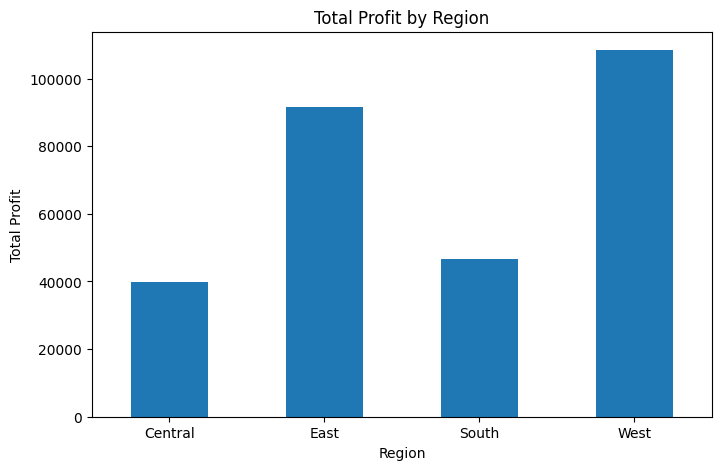

In [10]:
region_profit.plot(kind='bar', figsize=(8,5))

plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)

plt.show()